# Compactador Mermaid

## Objetivo

Traducir un texto simple organizado usando parentesis y transformarlos en diagramas de Mermaid.js 

## Alcance

- Generar distintos tipos de diagramas (de arbol): Permite crear mapas conceptuales,organigramas,modulos y diagramas de procesos lógicos (de flujos).
- Manejar estructuras jerárquicas ilimitadas: Procesar infinitos niveles de anidamiento y subordinación de ideas o pasos representados mediante paréntesis sucesivos.
- Simplificar  la complejidad de Mermaid: Permitir al usuario crear diagramas complejos mediante una sintaxis minimalista sin necesidad de escribir manualmente la sintaxis de grafos
- Gestionar flujos de decisión condicionales: Admitir ramificaciones etiquetadas mediante conectores directos (->) para flujos lógicos con respuestas afirmativas o negativas

## Ejemplos

**Ejemplo 1**

Entrada:

[MAPA]
(* Variable (Estática) (Dinámica))

Salida :

flowchart TD

    N0["Variable"]
    N0 --> N1
    N1["Estática"]  
    N0 --> N2 
    N2["Dinámica"]


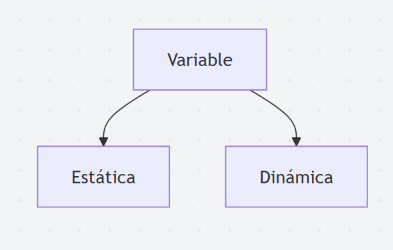


**Ejemplo 2**

Entrada :

[MAPA]
(*Paradigma (-imperativo (c) (pascla))
(-Objeto(java)(python))
(-Funcional(lips)(haskell))
(-logico(prolog)(datalog))
)

Salida:

flowchart TD

    N0["Paradigma"]
    N0 --> N1
    N1["imperativo"]
    N1 --> N2
    N2["c"]
    N1 --> N3
    N3["pascla"]
    N0 --> N4
    N4["Objeto"]
    N4 --> N5
    N5["java"]
    N4 --> N6
    N6["python"]
    N0 --> N7
    N7["Funcional"]
    N7 --> N13
    N13["lips"]
    N7 --> N9
    N9["haskell"]
    N0 --> N14
    N14["logico"]
    N14 --> N11
    N11["prolog"]
    N14 --> N15
    N15["datalog"]

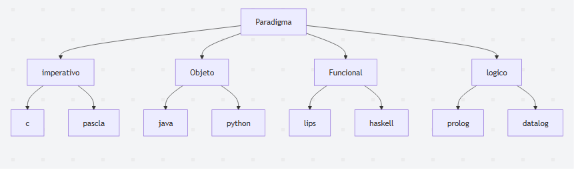


## Especificaciones Léxicas

|  Lexema   |  Token    | Patrón    | 
|-----------|-----------|-----------| 
| [MAPA]    | HEAD_MAPA | `\[MAPA\]` | 
| [ORGANIGRAMA] | HEAD_ORG | `\[ORGANIGRAMA\]`|
| [MODULOS]  | HEAD_MOD | `\[MODULOS\]`|
| [FLUJO] |  HEAD_FLUJO | `\[FLUJO\]`|
|  ( | PAR_ABRE | `\(` |
| ) | PAR_CIERRA |` \)`|
| * | PREF_PRINC|` \*`|
| - | PREF_SEC|` \-`|
| ?|OP_DECISION | `\?`|
|-> | OP_FLECHA | `\->`|
|TEXTO EN GENERAL| TEXTO|[a-zA-Z0-9_áéíóúÁÉÍÓÚñÑ\s.:,¿][a-zA-Z0-9_áéíóúÁÉÍÓÚñÑ\s.:,¿?]*|
|"texto literal"|TEXTO| \"[^\"\n]+\"|








## Especificaciones sintáctica

`<Programa>      ::= <Cabecera> <Nodo>`

`<Cabecera>      ::= HEAD_MAPA `
                 ` | HEAD_ORG `
                 ` | HEAD_MOD `
                 ` | HEAD_FLUJO`

`<Nodo>          ::= PAR_ABRE <ContenidoNodo> PAR_CIERRA `

`<ContenidoNodo> ::= <Modificador> TEXTO <ListaHijos>`
               `   | TEXTO <ListaHijos>`
                `  | TEXTO OP_FLECHA <Nodo>`

`<Modificador>   ::= PREF_PRINC `
               `   | PREF_SEC `
                `  | OP_DECISION`

`<ListaHijos>    ::= <Nodo> <ListaHijos>`
               `   | λ `

**Palabras** : [MAPA] (Prueba) , [FLUJO] (?¿A?(Si->(B)))

## Especificaciones Semánticas


| Regla Sintáctica | Acción Semántica Real (Enfoque Híbrido Python + LLM) |
| :--- | :--- |
| `<Programa> ::= <Cabecera> <Nodo>` | **Inicialización y Salida:** Captura el token de la cabecera para asignar de forma automática la orientación de Mermaid (`flowchart TD` o `flowchart LR`). Recibe el árbol final y exporta las líneas de código unificadas. |
| `<Cabecera> ::= HEAD_MAPA \| HEAD_ORG \| HEAD_FLUJO` | **Mapeo de Dirección:** Fuerza al motor a inicializar el diagrama bajo la directiva vertical **`flowchart TD`** (*Top-Down*). |
| `<Cabecera> ::= HEAD_MOD` | **Mapeo de Dirección:** Fuerza al motor a inicializar el diagrama bajo la directiva horizontal **`flowchart LR`** (*Left-to-Right*). |
| `<Nodo> ::= PAR_ABRE <ContenidoNodo> PAR_CIERRA` | **Aislamiento de Árbol:** Encapsula el bloque evaluado y propaga la estructura JSON hacia los nodos superiores. |
| `<ContenidoNodo> ::= <Modificador> TEXTO <ListaHijos>` | **Indexación y Geometría:** El campo `TEXTO` es enviado a Ollama para su traducción a un ID estable (`N0`, `N1`). Al procesar el modificador `?`, Python intercepta el flujo y envuelve el texto con llaves curvas **`N2{"Texto"}`** para generar el rombo de decisión. |
| `<ContenidoNodo> ::= TEXTO <ListaHijos>` | **Declaración Estándar:** El `TEXTO` se indexa con su ID a través de Ollama. Python lo envuelve con corchetes **`N0["Texto"]`** para crear un rectángulo común en el grafo. |
| `<ContenidoNodo> ::= TEXTO OP_FLECHA <Nodo>` | **Inyección de Etiquetas:** Captura el `TEXTO` previo a la flecha. Python suspende la creación de un nodo común e inyecta esa palabra como una **etiqueta de canal intermedia** dentro de la conexión (**`-- "TEXTO" -->`**). |
| `<ListaHijos> ::= <Nodo> <ListaHijos>` | **Trazado Recursivo:** Python recorre secuencialmente la lista y escribe las flechas de enlace directo (`-->`) desde el ID del nodo padre hacia los IDs de cada uno de sus hijos. |
| `<ListaHijos> ::= λ` | **Cierre Jerárquico:** Frena la recursión indicando que el nodo actual es una hoja terminal (no posee más dependencias bajo su jerarquía). |


## Implementación

In [1]:
%%file lexer_compactador.py

import ply.lex as lex


tokens = (
    'HEAD_MAPA',
    'HEAD_ORG',
    'HEAD_MOD',
    'HEAD_FLUJO',
    'PAR_ABRE',
    'PAR_CIERRA',
    'PREF_PRINC',
    'PREF_SEC',
    'OP_DECISION',
    'OP_FLECHA',
    'TEXTO'
)

# Expresiones regulares 
t_PAR_ABRE   = r'\('
t_PAR_CIERRA = r'\)'

# Cabeceras 
def t_HEAD_MAPA(t):
    r'\[MAPA\]'
    return t

def t_HEAD_ORG(t):
    r'\[ORGANIGRAMA\]'
    return t

def t_HEAD_MOD(t):
    r'\[MODULOS\]'
    return t

def t_HEAD_FLUJO(t):
    r'\[FLUJO\]'
    return t

# Cadena literal entrecomillada
def t_TEXTO_ENTRECOMILLADO(t):
    r'\"[^\"\n]+\"'
    t.type = 'TEXTO'          
    t.value = t.value[1:-1]   
    return t



def t_OP_FLECHA(t):
    r'\->'
    return t

# Modificadores como funciones 
def t_PREF_PRINC(t):
    r'\*'
    return t

def t_PREF_SEC(t):
    r'\-'
    return t

def t_OP_DECISION(t):
    r'\?'
    return t


def t_TEXTO(t):
    r'[a-zA-Z0-9_áéíóúÁÉÍÓÚñÑ\s\.:,¿][a-zA-Z0-9_áéíóúÁÉÍÓÚñÑ\s\.:,¿\?]*'
    t.value = t.value.strip()
    if not t.value:
        return None
    return t

# Seguimiento de número de línea para mensajes de error precisos
def t_newline(t):
    r'\n+'
    t.lexer.lineno += len(t.value)

# Ignorar espacios, tabulaciones 
t_ignore = ' \t\r'

# Manejo de errores léxicos
def t_error(t):
    print(f"Error léxico: Carácter ilegal '{t.value[0]}' en la línea {t.lineno}")
    t.lexer.skip(1)


lexer = lex.lex()




Writing lexer_compactador.py


In [2]:
%%file parser_compactador.py
import ply.yacc as yacc
from lexer_compactador import tokens


def p_programa(p):
    '''programa : cabecera nodo'''
    p[0] = {
        "tipo_diagrama": p[1],
        "arbol_jerarquico": p[2]
    }


def p_cabecera(p):
    '''cabecera : HEAD_MAPA
                | HEAD_ORG
                | HEAD_MOD
                | HEAD_FLUJO'''
    p[0] = p[1]


def p_nodo(p):
    '''nodo : PAR_ABRE contenido_nodo PAR_CIERRA'''
    p[0] = p[2]


def p_contenido_nodo_con_modificador(p):
    '''contenido_nodo : modificador TEXTO lista_hijos'''
    p[0] = {
        "texto": p[2],
        "modificador": p[1],
        "hijos": p[3],
        "tipo": "nodo_modificado"
    }

def p_contenido_nodo_estandar(p):
    '''contenido_nodo : TEXTO lista_hijos'''
    p[0] = {
        "texto": p[1],
        "modificador": None,
        "hijos": p[2],
        "tipo": "nodo_estandar"
    }

def p_contenido_nodo_flecha_condicional(p):
    '''contenido_nodo : TEXTO OP_FLECHA nodo'''
    p[0] = {
        "etiqueta_flecha": p[1],
        "nodo_destino": p[3],
        "tipo": "flujo_condicional"
    }


def p_modificador(p):
    '''modificador : PREF_PRINC
                   | PREF_SEC
                   | OP_DECISION'''
    p[0] = p[1]


def p_lista_hijos_recursiva(p):
    '''lista_hijos : nodo lista_hijos'''
    p[0] = [p[1]] + p[2]

def p_lista_hijos_vacia(p):
    '''lista_hijos : '''
    p[0] = []  # Representa lambda (λ), fin de la recursión

# Manejo de errores sintácticos
def p_error(p):
    if p:
        print(f"Error sintáctico: Token inesperado '{p.value}' de tipo {p.type}")
    else:
        print("Error sintáctico: Fin de archivo inesperado. ¿Te olvidaste de cerrar algún paréntesis?")

# Construir el parser
parser = yacc.yacc()


Overwriting parser_compactador.py


In [7]:
%%file generador_mermaid.py
import json
import ollama

def extraer_textos_unicos(nodo, lista_textos=None):
    if lista_textos is None:
        lista_textos = []
    if not nodo:
        return lista_textos

    texto = nodo.get("texto")
    if texto and texto not in lista_textos:
        lista_textos.append(texto)

    for hijo in nodo.get("hijos", []):
        if hijo.get("tipo") == "flujo_condicional":
            extraer_textos_unicos(hijo.get("nodo_destino"), lista_textos)
        else:
            extraer_textos_unicos(hijo, lista_textos)

    return lista_textos

def obtener_mapeo_ids_con_ollama(ast_json):

    textos_unicos = extraer_textos_unicos(ast_json.get("arbol_jerarquico"))
    lista_string = json.dumps(textos_unicos, ensure_ascii=False)

    prompt_sistema = (
        "Eres el módulo léxico-semántico de un compilador. Recibirás una lista JSON de etiquetas de nodos. "
        "Debes asignar a CADA elemento de la lista un ID secuencial único (N0, N1, N2, etc.) en el mismo orden. "
        "Responde EXCLUSIVAMENTE con un objeto JSON plano donde la clave sea la etiqueta exacta y el valor sea su ID. "
        "Ejemplo: {\"Inicio\": \"N0\", \"Fin\": \"N1\"}"
    )

    response = ollama.chat(
        model='llama3.2',
        messages=[
            {'role': 'system', 'content': prompt_sistema},
            {'role': 'user', 'content': lista_string}
        ],
        format='json'
    )

    mapa_ids = json.loads(response['message']['content'])

    
    for texto in textos_unicos:
        if texto not in mapa_ids:
            mapa_ids[texto] = f"N{len(mapa_ids)}"

    return mapa_ids

def construir_lineas_mermaid(nodo, mapa_ids):
    lineas = []
    if not nodo:
        return lineas

    tipo = nodo.get("tipo")

    if tipo in ["nodo_estandar", "nodo_modificado"]:
        texto = nodo.get("texto")
        id_actual = mapa_ids.get(texto, "N_ERROR")
        modificador = nodo.get("modificador")

        if modificador == "?":
            lineas.append(f'    {id_actual}{{"{texto}"}}')
        else:
            lineas.append(f'    {id_actual}["{texto}"]')

        for hijo in nodo.get("hijos", []):
            if hijo.get("tipo") == "flujo_condicional":
                etiqueta = hijo.get("etiqueta_flecha")
                subnodo = hijo.get("nodo_destino")
                if subnodo:
                    sub_texto = subnodo.get("texto")
                    id_hijo = mapa_ids.get(sub_texto)
                    if id_hijo:
                        lineas.append(f'    {id_actual} -- "{etiqueta}" --> {id_hijo}')
                    lineas.extend(construir_lineas_mermaid(subnodo, mapa_ids))
            else:
                sub_texto = hijo.get("texto")
                id_hijo = mapa_ids.get(sub_texto)
                if id_hijo:
                    lineas.append(f'    {id_actual} --> {id_hijo}')
                lineas.extend(construir_lineas_mermaid(hijo, mapa_ids))

    return lineas

def traductor_stw_completo(ast_json):
    mapa_ids = obtener_mapeo_ids_con_ollama(ast_json)

    cabeceras_mermaid = {
        "[FLUJO]":"flowchart TD",
        "[ORGANIGRAMA]":"flowchart TD",
        "[MODULOS]":"flowchart LR",
        "[MAPA]":"flowchart TD"
    }



    cabecera_usuario = ast_json.get("tipo_diagrama", "[FLUJO]")
    directiva = cabeceras_mermaid.get(cabecera_usuario, "flowchart TD")

    cuerpo_diagrama = construir_lineas_mermaid(ast_json.get("arbol_jerarquico"), mapa_ids)

    lineas_unicas = []
    for linea in cuerpo_diagrama:
        if linea not in lineas_unicas:
            lineas_unicas.append(linea)

    return directiva + "\n" + "\n".join(lineas_unicas)


Overwriting generador_mermaid.py


In [1]:
%%file main.py
import sys
from lexer_compactador import lexer
from parser_compactador import parser
from generador_mermaid import traductor_stw_completo

def compilar_archivo(ruta_entrada):
    with open(ruta_entrada, 'r', encoding='utf-8') as f:
        entrada = f.read()

    
    lexer.lineno = 1
    ast = parser.parse(entrada, lexer=lexer)

    if not ast:
        salida = "Error sintáctico o léxico en el programa fuente"
    else:
        salida = traductor_stw_completo(ast)

    print(salida)
    with open(f"{ruta_entrada}.mmd", 'w', encoding='utf-8') as f_out:
        f_out.write(salida + '\n')

if __name__ == "__main__":
    if len(sys.argv) < 2:
        print("Uso: python main.py <archivo_entrada>")
        sys.exit(1)
    compilar_archivo(sys.argv[1])


Overwriting main.py


## Conclusiones

Este proyecto permitió comprender en profundidad la relación entre la sintaxis y la semántica, el rol de un meta-compilador y el uso responsable de la Inteligencia Artificial como un recurso potenciador. Desde el punto de vista práctico, la implementación del lenguaje **Compactador Mermaid** permitió evaluar tanto sus capacidades como sus limitaciones reales. 

Luego de realizar diversas pruebas de funcionamiento, se dedujo que:

* **Escalabilidad y recursos:** El compactador permite teóricamente la creación ilimitada de nodos hijos anidados, aunque en la práctica su procesamiento estará sujeto a las limitaciones físicas del hardware disponible (memoria y capacidad de cómputo).
* **Equilibrio entre potencia y simplicidad:** Su expansión hacia otros tipos de gráficos de Mermaid es acotada, ya que incorporar diagramas más avanzados exigiría reglas gramaticales mucho más complejas, lo que iría en contra del objetivo principal de mantener un lenguaje minimalista y fácil de escribir.
* **Versatilidad estructural:** A pesar de estar limitado a cuatro categorías (mapa conceptual, organigrama, arquitectura de módulos y diagrama de flujo), la contención por paréntesis estilo Lisp y la lógica del árbol de sintaxis abstracta brindan una gran flexibilidad para representar estructuras de datos complejas de manera clara y rápida.